# Model Evaluation: ROC, Confusion Matrix & Threshold Tuning

Evaluates classifier discriminative power, plots ROC/PR curves, displays confusion matrix, and visualizes threshold optimization.

**Generates:** `09_roc_pr_curves.png`, `10_confusion_matrices_comparison.png`, `11_threshold_tuning_curve.png`


### 1. Environment & Path Configuration

In [1]:
import os
import sys
import matplotlib.pyplot as plt
%matplotlib inline

# Navigate to project root if running from notebooks directory
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print('Active Project Root:', os.getcwd())


Active Project Root: e:\ML\mini project 2


### 2. Execution & Visualization Generation

Loading models/best_model_enhanced.joblib...
Loading dataset for evaluation...


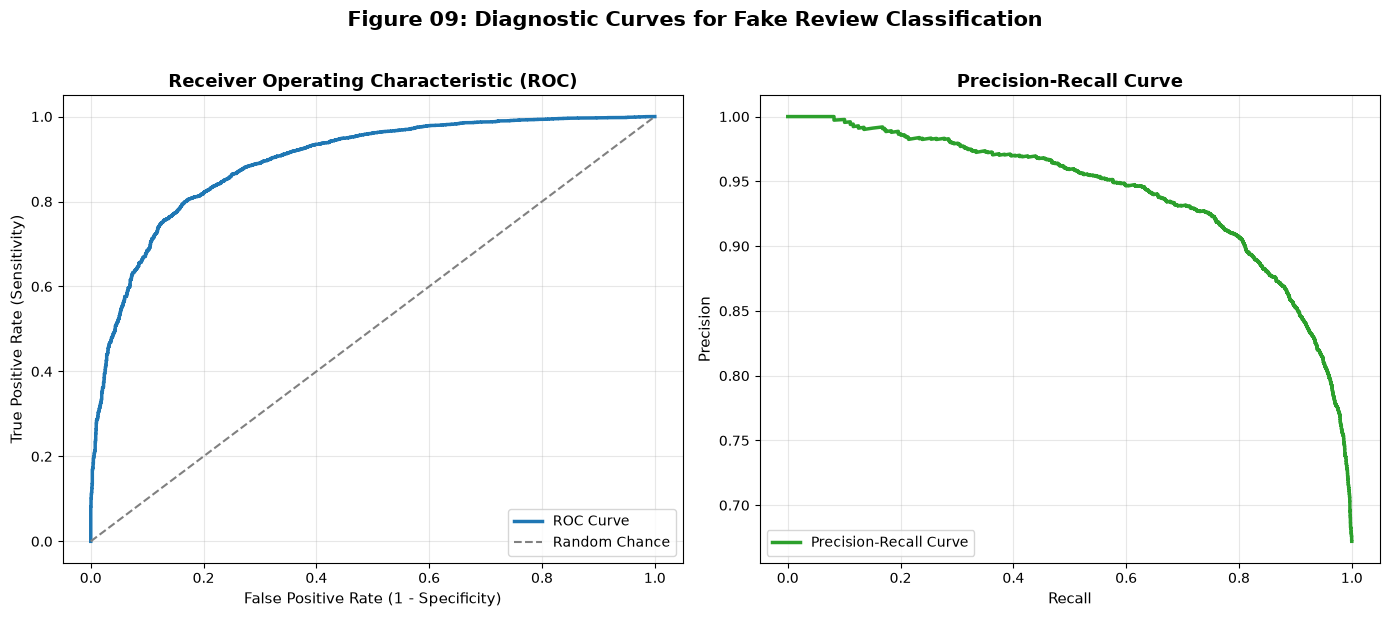

Saved: results/figures\09_roc_pr_curves.png


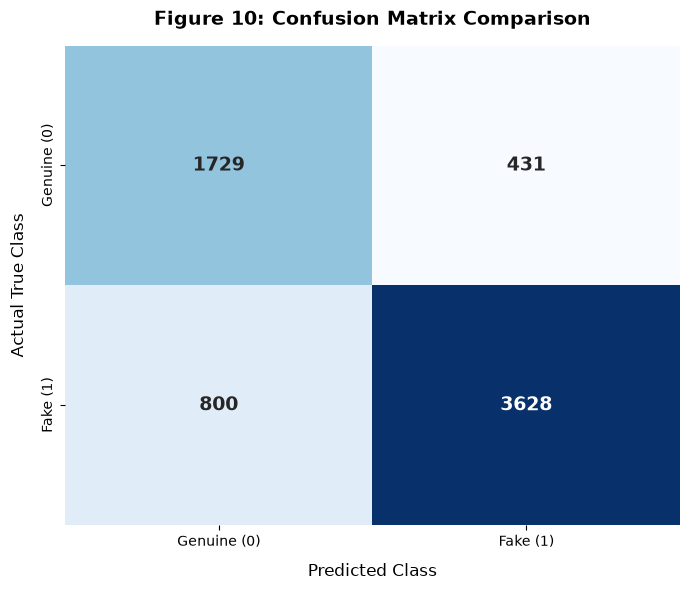

Saved: results/figures\10_confusion_matrices_comparison.png


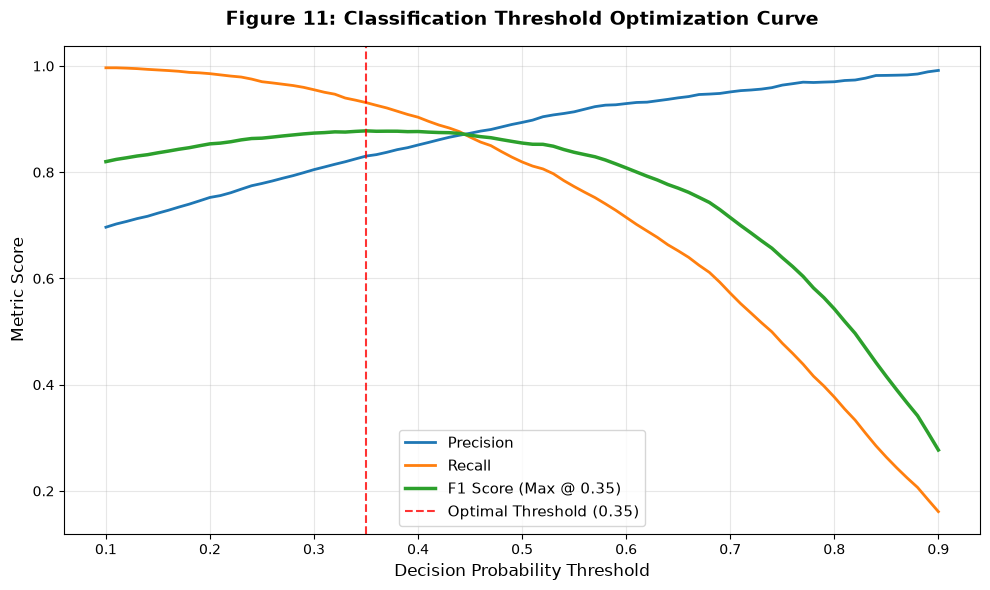

Saved: results/figures\11_threshold_tuning_curve.png


In [2]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

FIGURES_DIR = "results/figures"
METRICS_DIR = "results/metrics"
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

# Load production model
model_path = "models/best_model_enhanced.joblib"
print(f"Loading {model_path}...")
model = joblib.load(model_path)

# Load test dataset
print("Loading dataset for evaluation...")
df_he = pd.read_csv("dataset/cleaned_reviews.csv")
texts = (df_he["review_title"].fillna("").astype(str) + " " + df_he["review_text"].fillna("").astype(str)).str.strip()
labels = df_he["label"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.2, random_state=42, stratify=labels)

y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

# -------------------------------------------------------------
# 1. Figure 09: ROC & Precision-Recall Curves
# -------------------------------------------------------------
fpr, tpr, _ = roc_curve(y_test, y_prob)
precision, recall, _ = precision_recall_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].plot(fpr, tpr, color='#1f77b4', lw=2.5, label='ROC Curve')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Random Chance')
axes[0].set_title('Receiver Operating Characteristic (ROC)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
axes[0].set_ylabel('True Positive Rate (Sensitivity)', fontsize=11)
axes[0].legend(loc='lower right', frameon=True)
axes[0].grid(True, alpha=0.3)

axes[1].plot(recall, precision, color='#2ca02c', lw=2.5, label='Precision-Recall Curve')
axes[1].set_title('Precision-Recall Curve', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].legend(loc='lower left', frameon=True)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Figure 09: Diagnostic Curves for Fake Review Classification', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "09_roc_pr_curves.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(METRICS_DIR, "09_roc_pr_curves.png"), dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {os.path.join(FIGURES_DIR, '09_roc_pr_curves.png')}")

# -------------------------------------------------------------
# 2. Figure 10: Confusion Matrix
# -------------------------------------------------------------
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Genuine (0)', 'Fake (1)'],
            yticklabels=['Genuine (0)', 'Fake (1)'],
            annot_kws={'size': 14, 'weight': 'bold'}, ax=ax)
ax.set_title('Figure 10: Confusion Matrix Comparison', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Predicted Class', fontsize=12, labelpad=10)
ax.set_ylabel('Actual True Class', fontsize=12, labelpad=10)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "10_confusion_matrices_comparison.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(METRICS_DIR, "10_confusion_matrices_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {os.path.join(FIGURES_DIR, '10_confusion_matrices_comparison.png')}")

# -------------------------------------------------------------
# 3. Figure 11: Threshold Tuning Curve
# -------------------------------------------------------------
thresholds = np.linspace(0.1, 0.9, 81)
precisions, recalls, f1s = [], [], []

for th in thresholds:
    preds = (y_prob >= th).astype(int)
    tp = np.sum((preds == 1) & (y_test == 1))
    fp = np.sum((preds == 1) & (y_test == 0))
    fn = np.sum((preds == 0) & (y_test == 1))
    p = tp / (tp + fp) if (tp + fp) > 0 else 0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0
    precisions.append(p)
    recalls.append(r)
    f1s.append(f1)

optimal_idx = np.argmax(f1s)
optimal_th = thresholds[optimal_idx]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(thresholds, precisions, label='Precision', color='#1f77b4', lw=2)
ax.plot(thresholds, recalls, label='Recall', color='#ff7f0e', lw=2)
ax.plot(thresholds, f1s, label=f'F1 Score (Max @ {optimal_th:.2f})', color='#2ca02c', lw=2.5)
ax.axvline(optimal_th, color='red', linestyle='--', label=f'Optimal Threshold ({optimal_th:.2f})', alpha=0.8)
ax.set_title('Figure 11: Classification Threshold Optimization Curve', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Decision Probability Threshold', fontsize=12)
ax.set_ylabel('Metric Score', fontsize=12)
ax.legend(loc='lower center', frameon=True, fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "11_threshold_tuning_curve.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(METRICS_DIR, "11_threshold_tuning_curve.png"), dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {os.path.join(FIGURES_DIR, '11_threshold_tuning_curve.png')}")
